In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

In [5]:
data_path = Path(r"C:\Users\nived\EntriModule2Assignments\ABC Company Dataset.csv")
df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (458, 9)


,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,06-Feb,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,06-Jun,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,06-May,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,06-May,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,06-Oct,231,NaN,5000000.0


In [6]:
df.info()
display(df.isnull().sum().to_frame("Missing Values"))
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      458 non-null    object 
 1   Team      458 non-null    object 
 2   Number    458 non-null    int64  
 3   Position  458 non-null    object 
 4   Age       458 non-null    int64  
 5   Height    458 non-null    object 
 6   Weight    458 non-null    int64  
 7   College   374 non-null    object 
 8   Salary    447 non-null    float64
dtypes: float64(1), int64(3), object(5)
memory usage: 32.3+ KB


,Missing Values
Name,0
Team,0
Number,0
Position,0
Age,0
Height,0
Weight,0
College,84
Salary,11


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,458,458,Priyanka,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Team,458,30,New Orleans Pelicans,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number,458.0,NaN,NaN,NaN,17.713974,15.966837,0.0,5.0,13.0,25.0,99.0
Position,458,5,SG,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,458.0,NaN,NaN,NaN,26.934498,4.400128,19.0,24.0,26.0,30.0,40.0
Height,458,18,06-Sep,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weight,458.0,NaN,NaN,NaN,221.543668,26.3432,161.0,200.0,220.0,240.0,307.0
College,374,118,Kentucky,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Salary,447.0,NaN,NaN,NaN,4833969.545861,5226620.431854,30888.0,1025210.5,2836186.0,6500000.0,25000000.0


## 1. Preprocessing – replace height values

In [7]:
ran_int = np.random.default_rng(42)
df['Height'] = ran_int.integers(150,181, size=len(df))

print(df['Height'].describe())
display(df[["Name", "Height"]].head())
                                

count    458.000000
mean     164.884279
std        8.868461
min      150.000000
25%      158.000000
50%      165.000000
75%      173.000000
max      180.000000
Name: Height, dtype: float64


,Name,Height
0,Avery Bradley,152
1,Jae Crowder,173
2,John Holland,170
3,R.J. Hunter,163
4,Jonas Jerebko,163


## 2.1 Analysis 1 – employee distribution across teams

In [8]:
team_summary = (df['Team'].value_counts().rename_axis("Team").reset_index(name="Employee Count"))
team_summary['Percentage'] = team_summary['Employee Count']/ len(df) *100

team_summary

,Team,Employee Count,Percentage
0,New Orleans Pelicans,19,4.148472
1,Memphis Grizzlies,18,3.930131
2,Utah Jazz,16,3.493450
3,Milwaukee Bucks,16,3.493450
4,New York Knicks,16,3.493450
5,Boston Celtics,15,3.275109
6,Los Angeles Clippers,15,3.275109
7,Los Angeles Lakers,15,3.275109
8,Phoenix Suns,15,3.275109
9,Sacramento Kings,15,3.275109


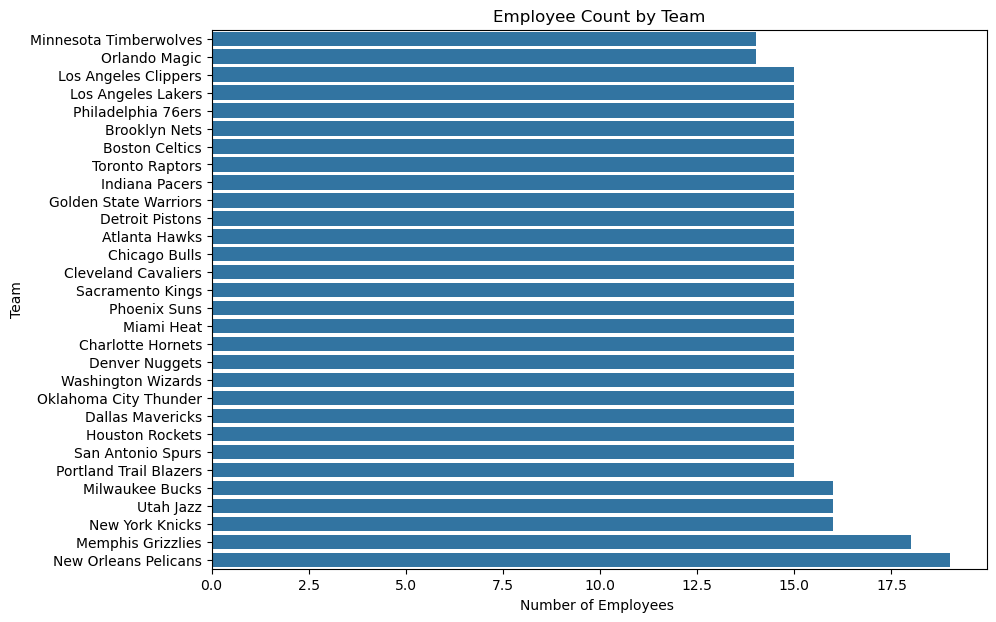

In [9]:
plt.figure(figsize=(10,7))
sns.barplot(data=team_summary.sort_values('Employee Count'), x='Employee Count', y="Team")
plt.title("Employee Count by Team")
plt.xlabel("Number of Employees ")
plt.ylabel("Team")
plt.show()

## 2.2 Analysis 2 – employees by position

,Position,Employee Count,Percentage
0,SG,102,22.270742
1,PF,100,21.834061
2,PG,92,20.087336
3,SF,85,18.558952
4,C,79,17.248908


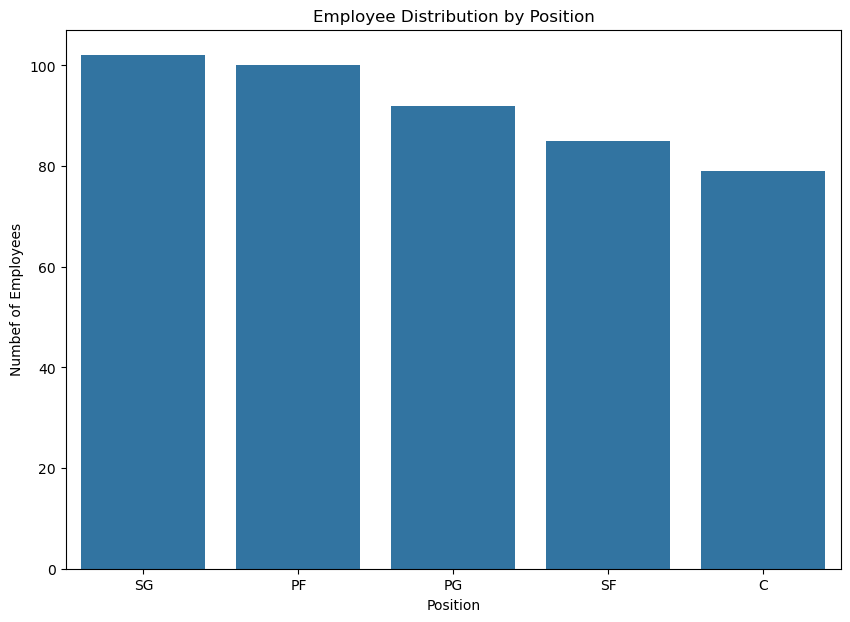

In [10]:
position_summary = (df["Position"].value_counts().rename_axis("Position").reset_index(name='Employee Count'))

position_summary['Percentage'] = position_summary['Employee Count']/ len(df) *100
display(position_summary)
plt.figure(figsize=(10,7))
sns.barplot(data=position_summary, x='Position', y='Employee Count')
plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Numbef of Employees")
plt.show()

## 2.3 – Predominant age group

,Age Group,Employee Count,Percentage
0,Under 20,2,0.436681
1,20-29,334,72.925764
2,30-39,119,25.982533
3,40+,3,0.655022


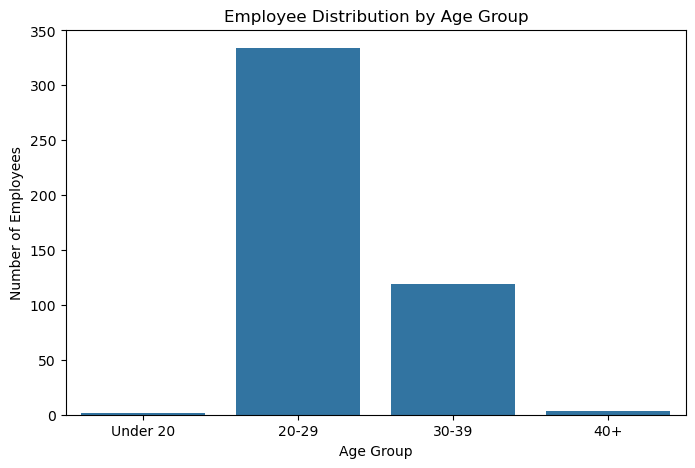

In [11]:
age = [18,20,30,40,float("inf")]
age_labels = ['Under 20', '20-29', '30-39', '40+']

df['Age Group'] = pd.cut(df["Age"], bins=age, labels=age_labels, right= False)

age_summary = (df["Age Group"].value_counts()
      .reindex(age_labels, fill_value=0)
      .rename_axis("Age Group")
      .reset_index(name="Employee Count"))
age_summary["Percentage"] =age_summary['Employee Count']/len(df)*100
display(age_summary)

plt.figure(figsize=(8, 5))
sns.barplot(data=age_summary, x="Age Group", y="Employee Count")
plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.show()


## 2.4 – Salary expenditure by team and position

,Team,Total Salary
0,Cleveland Cavaliers,106988689.0
1,Los Angeles Clippers,94854640.0
2,Oklahoma City Thunder,93765298.0
3,Golden State Warriors,88868997.0
4,Chicago Bulls,86783378.0
5,San Antonio Spurs,84442733.0
6,New Orleans Pelicans,82750774.0
7,Miami Heat,82515673.0
8,Charlotte Hornets,78340920.0
9,Memphis Grizzlies,76550880.0


,Position,Total Salary
0,C,466377332.0
1,PG,446848971.0
2,PF,442560850.0
3,SF,408020976.0
4,SG,396976258.0


Highest team expenditure: Cleveland Cavaliers (106,988,689)
Highest position expenditure: C (466,377,332)


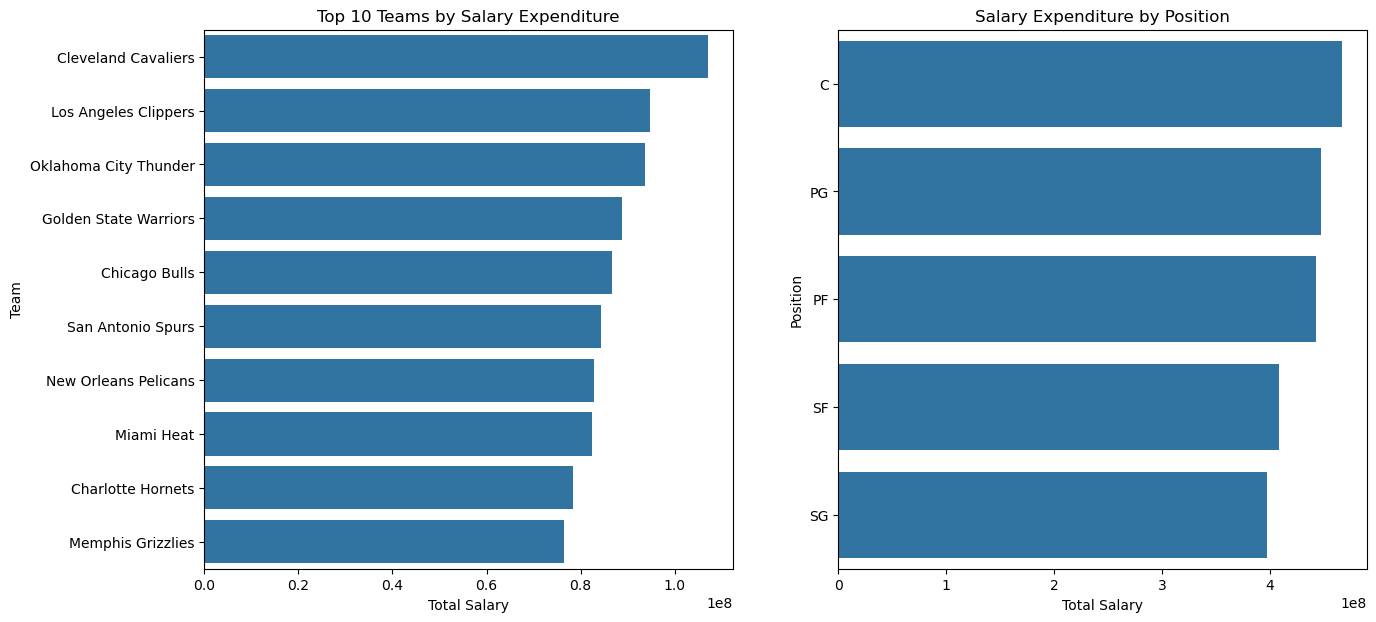

In [12]:
team_salary = (df.groupby("Team")["Salary"].sum()
                 .sort_values(ascending=False)
                 .rename("Total Salary")
                 .reset_index())
position_salary = (df.groupby("Position")["Salary"].sum()
                     .sort_values(ascending=False)
                     .rename("Total Salary")
                     .reset_index())

display(team_salary.head(10))
display(position_salary)

highest_team = team_salary.iloc[0]
highest_position = position_salary.iloc[0]
print(f"Highest team expenditure: {highest_team['Team']} "
      f"({highest_team['Total Salary']:,.0f})")
print(f"Highest position expenditure: {highest_position['Position']} "
      f"({highest_position['Total Salary']:,.0f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.barplot(data=team_salary.head(10), x="Total Salary", y="Team", ax=axes[0])
axes[0].set_title("Top 10 Teams by Salary Expenditure")
sns.barplot(data=position_salary, x="Total Salary", y="Position", ax=axes[1])
axes[1].set_title("Salary Expenditure by Position")
plt.show()

## 2.5 – correlation between age and salary

Pearson correlation between Age and Salary: 0.214


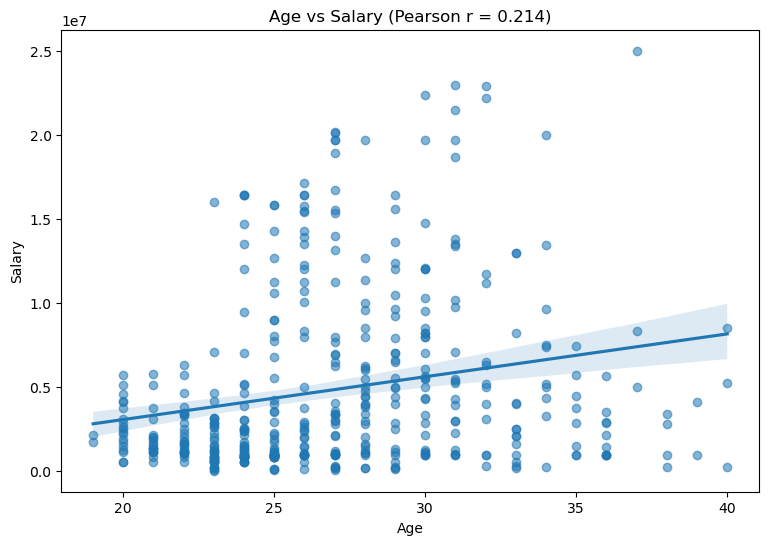

In [13]:
age_salary = df[["Age", "Salary"]].dropna()
correlation = age_salary["Age"].corr(age_salary["Salary"])
print(f"Pearson correlation between Age and Salary: {correlation:.3f}")

plt.figure(figsize=(9, 6))
sns.regplot(data=age_salary, x="Age", y="Salary",
            scatter_kws={"alpha": 0.55})
plt.title(f"Age vs Salary (Pearson r = {correlation:.3f})")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

##  Save the cleaned dataset

In [18]:
output_path = Path(r"C:\Users\nived\EntriModule2Assignments\cleaned_dataset.csv")
df.drop(columns=["Age Group"]).to_csv(output_path, index=False)
print("Cleaned dataset saved to:", output_path)


Cleaned dataset saved to: C:\Users\nived\EntriModule2Assignments\cleaned_dataset.csv
